# Task 4: Game Title Detection (Image Classification)

**เป้าหมาย:** จำแนกภาพหน้าจอเกม (230×120 พิกเซล) ว่าเป็นเกมใดใน 5 เกม ได้แก่ 0: 7-11 Knights, 1: FiveN, 2: Free Fried, 3: PUBE, 4: Roblock

**Metric:** macro F1

**ประเด็นสำคัญของโจทย์:** datacard ระบุว่าภาพมาจากหลายแหล่ง (ไลฟ์สตรีม, ผู้เล่นส่งมา, ฟอรัม, ตั๋วแจ้งปัญหา) คุณภาพของภาพจึงไม่สม่ำเสมอ
ทั้งความเบลอ การบีบอัด JPEG สัญญาณรบกวน และมุมหรือการครอปที่ต่างกัน
โมเดลที่ได้ F1 ราว 0.99 บน validation ที่เป็นภาพสะอาดจึงยังไม่พอ ต้องฝึกให้ทนต่อการเสื่อมคุณภาพของภาพแบบทั่วไป (generic robustness augmentation) และรวมโมเดลหลายสถาปัตยกรรม

**โครงสร้างของโฟลเดอร์นี้**
- `train.py`: สคริปต์ fine-tune โมเดล pretrained จาก `timm` ทีละ fold (ต้องใช้ GPU)
- `train_all.sh`: คำสั่งฝึกโมเดลทั้งหมดที่ใช้ในโน้ตบุ๊กนี้ (โมเดลละ 5 fold)
- `pack_preds.py`: รวมผลทำนายราย fold เป็นไฟล์ `preds/<tag>.npz`
- `preds/`: ความน่าจะเป็น OOF และ test ของโมเดลที่ฝึกเสร็จแล้ว (ใช้สร้างคำตอบได้ทันทีโดยไม่ต้องฝึกใหม่)
- `task4.ipynb` (โน้ตบุ๊กนี้): อธิบายวิธี ตรวจสอบคะแนน เลือกการรวมโมเดล และสร้างไฟล์คำตอบ

การใช้โมเดล pretrained อนุญาตเฉพาะ Task 4 ตามกติกาการแข่งขัน

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, confusion_matrix

DATA = Path(os.environ.get('CPE342_DATA', '../data')) / '04_image_classification'
OUT = Path('output'); OUT.mkdir(exist_ok=True)
CLASSES = ['7-11 Knights', 'FiveN', 'Free Fried', 'PUBE', 'Roblock']

train = pd.read_csv(DATA / 'train.csv')
test = pd.read_csv(DATA / 'test.csv')
y = train['label'].values
print('train images:', len(train), '| test images:', len(test))

train images: 31546 | test images: 25889


## 1. ข้อมูล

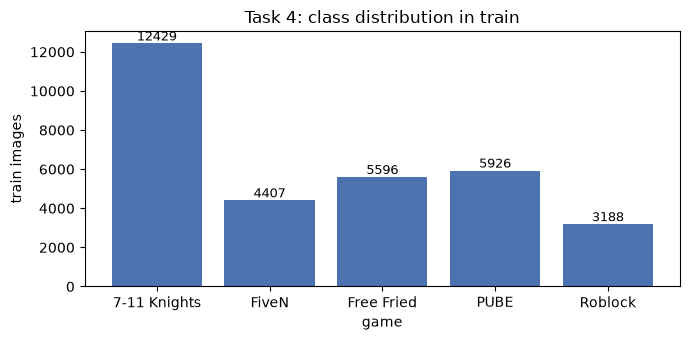

In [2]:
fig, ax = plt.subplots(figsize=(7, 3.5))
cnt = pd.Series(y).value_counts().sort_index()
ax.bar(CLASSES, cnt.values, color='#4C72B0')
for i, v in enumerate(cnt.values):
    ax.text(i, v, str(v), ha='center', va='bottom', fontsize=9)
ax.set_xlabel('game'); ax.set_ylabel('train images'); ax.set_title('Task 4: class distribution in train')
plt.tight_layout(); plt.show()

คลาสใน train ไม่สมดุลชัดเจน 7-11 Knights มีมากที่สุด (ราว 39% ของภาพ) ส่วน Roblock มีน้อยที่สุด (ราว 10%)
จึงใช้ StratifiedKFold เพื่อให้ทุก fold มีสัดส่วนคลาสเท่ากัน และวัดผลด้วย macro F1 ซึ่งให้น้ำหนักทุกเกมเท่ากัน

ตัวอย่างภาพจาก train ด้านล่างแสดงว่าภาพในชุดเดียวกันมีความหลากหลายมาก ทั้งการหมุนและครอป สัญญาณรบกวน ความเบลอ
และสีที่เพี้ยนไปจากปกติ (บางภาพสีถูกหมุนหรือกลับสี) โมเดลจึงต้องจดจำลักษณะของเกม (UI, ฉาก, ตัวละคร) ไม่ใช่จดจำสีหรือคุณภาพของภาพ

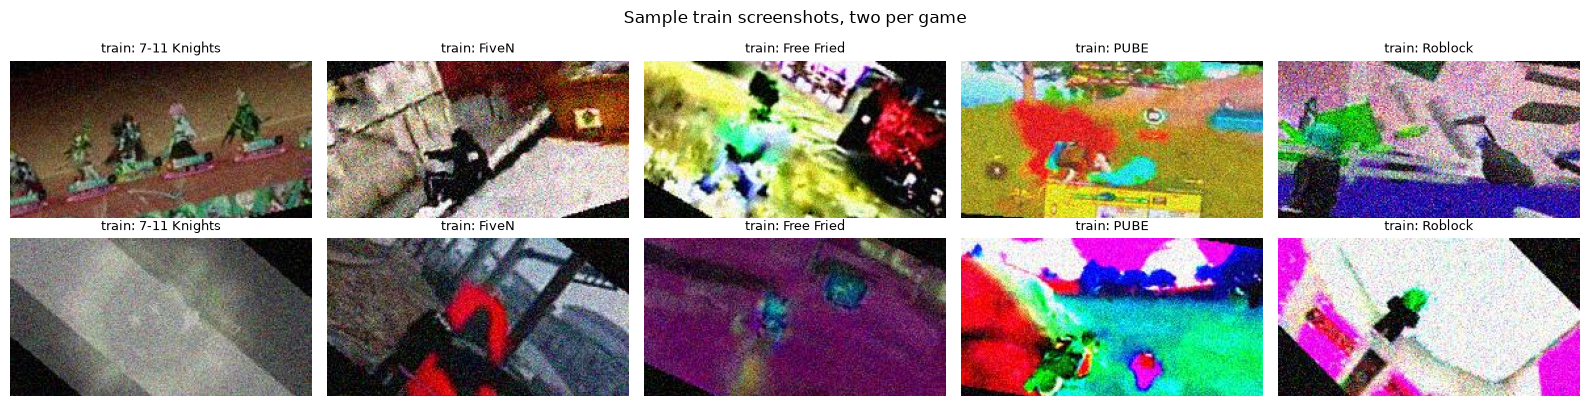

In [3]:
from PIL import Image
if (DATA / 'train').exists():
    rng = np.random.default_rng(0)
    fig, axes = plt.subplots(2, 5, figsize=(16, 4.2))
    for c in range(5):
        for r, i in enumerate(rng.choice(np.where(y == c)[0], 2, replace=False)):
            axes[r, c].imshow(Image.open(DATA / 'train' / train.file_name[i]))
            axes[r, c].set_title(f'train: {CLASSES[c]}', fontsize=9)
    for a in axes.ravel():
        a.axis('off')
    fig.suptitle('Sample train screenshots, two per game'); plt.tight_layout(); plt.show()
else:
    print('Image folder not found; download the Task 4 images into data/04_image_classification/{train,test}.')

## 2. วิธีการฝึกโมเดล (`train.py`)

**Validation:** StratifiedKFold 5 fold (`random_state=42`) ชุดเดียวกันทุกโมเดล เพื่อให้นำ OOF มารวมกันและเปรียบเทียบได้อย่างยุติธรรม

**การฝึก:** fine-tune โมเดล pretrained ทั้งตัวด้วย AdamW (weight decay 0.05), OneCycle learning rate, label smoothing 0.1,
gradient clipping, mixed precision (bf16) และเก็บค่าเฉลี่ยแบบ EMA ของน้ำหนัก (decay 0.999) เพื่อให้โมเดลนิ่งขึ้น

**Augmentation สำหรับความทนทาน (`T4_AUG=5`):** สุ่มรวมการเสื่อมคุณภาพแบบทั่วไปตามตระกูลของ ImageNet-C ซึ่งสอดคล้องกับแหล่งที่มาของภาพใน datacard
- เรขาคณิต: zoom-out บนพื้นหลังสุ่มสี, หมุน, perspective, random resized crop (scale 0.3 ถึง 1.0), พลิกแนวนอน
- สีและแสง: color jitter ระดับมาตรฐาน (brightness, contrast, saturation 0.3 และ hue 0.05)
- คุณภาพภาพ: Gaussian blur, motion blur, median/sharpen filter, pixelate, JPEG คุณภาพต่ำ, Gaussian noise, random erasing

`T4_AUG=6` คือชุดเดียวกันแต่เพิ่มความถี่และเพิ่ม defocus, haze และ shot noise

**การเลือก epoch:** แต่ละ epoch ประเมิน validation fold สามแบบ คือภาพสะอาด (clean), ภาพที่ผ่านการเสื่อมคุณภาพแบบสุ่มด้วย seed คงที่ (degraded proxy: pixelate, JPEG, blur, noise)
และภาพที่ผ่านการเสื่อมทางเรขาคณิต (geo proxy) แล้วเก็บ checkpoint ที่ degraded proxy ดีที่สุด ทุก proxy สร้างจากภาพ train ใน validation fold เท่านั้น

**การทำนาย test:** เฉลี่ยความน่าจะเป็นของภาพปกติกับภาพพลิกแนวนอน (flip TTA) แล้วเฉลี่ยข้าม 5 fold

In [4]:
MODELS = pd.DataFrame([
    ['el5', 'eva02_large_patch14_448.mim_m38m_ft_in22k_in1k', '224x448', 2e-5, 16, 10, 5],
    ['cl5', 'convnextv2_large.fcmae_ft_in22k_in1k', '160x320', 1e-4, 32, 18, 5],
    ['eb5', 'eva02_base_patch14_448.mim_in22k_ft_in22k_in1k', '224x448', 5e-5, 32, 18, 5],
], columns=['tag', 'timm model', 'input size', 'peak lr', 'batch', 'epochs', 'aug'])
MODELS

,tag,timm model,input size,peak lr,batch,epochs,aug
0,el5,eva02_large_patch14_448.mim_m38m_ft_in22k_in1k,224x448,0.00002,16,10,5
1,cl5,convnextv2_large.fcmae_ft_in22k_in1k,160x320,0.00010,32,18,5
2,eb5,eva02_base_patch14_448.mim_in22k_ft_in22k_in1k,224x448,0.00005,32,18,5


`el5` คือ EVA02 Large, `cl5` คือ ConvNeXt V2 Large และ `eb5` คือ EVA02 Base ทั้งสามใช้ augmentation ชุดเดียวกัน (AUG 5)
การฝึกใหม่ใช้ GPU ราว 2 ถึง 2.5 ชั่วโมงต่อ fold สำหรับ EVA02 Large, ราว 1.5 ถึง 1.8 ชั่วโมงต่อ fold สำหรับ ConvNeXt V2 Large และราว 1.2 ชั่วโมงต่อ fold สำหรับ EVA02 Base
(บน NVIDIA L40 หรือ RTX 4090) รวมประมาณ 27 GPU-ชั่วโมง

ผลทำนายที่ฝึกเสร็จแล้วอยู่ใน `preds/` โน้ตบุ๊กนี้จึงตั้งค่าเริ่มต้นให้ไม่ฝึกใหม่ หากต้องการฝึกใหม่ให้ตั้ง `RUN_TRAINING = True` บนเครื่องที่มี CUDA GPU

In [5]:
RUN_TRAINING = False
if RUN_TRAINING:
    import subprocess
    subprocess.run(['bash', 'train_all.sh'], check=True)
    subprocess.run(['python', 'pack_preds.py', *MODELS.tag], check=True)

## 3. คะแนน OOF ของแต่ละโมเดล

In [6]:
P = {t: dict(np.load(f'preds/{t}.npz')) for t in MODELS.tag}
f1 = lambda p: f1_score(y, p.argmax(1), average='macro')
rows = []
for t, d in P.items():
    assert (d['fold'] >= 0).all()
    rows.append([t, f1(d['oof']), f1(d['oofc']), f1(d['oofg'])])
scores = pd.DataFrame(rows, columns=['model', 'clean OOF F1', 'degraded OOF F1', 'geo OOF F1']).set_index('model')
scores.round(4)

,clean OOF F1,degraded OOF F1,geo OOF F1
model,,,
el5,0.9929,0.9911,0.9861
cl5,0.9933,0.9901,0.9842
eb5,0.9907,0.9892,0.9835


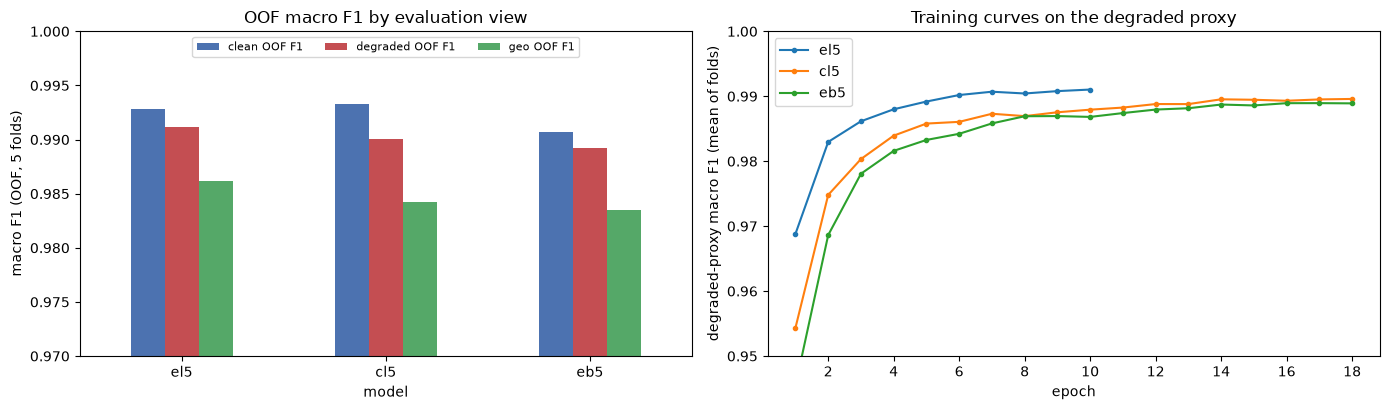

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
scores.plot.bar(ax=axes[0], rot=0, color=['#4C72B0', '#C44E52', '#55A868'])
axes[0].set_ylim(0.97, 1.0); axes[0].set_ylabel('macro F1 (OOF, 5 folds)'); axes[0].set_xlabel('model')
axes[0].set_title('OOF macro F1 by evaluation view'); axes[0].legend(loc='upper center', ncol=3, fontsize=8)
for t in MODELS.tag:
    lg = pd.read_csv(f'preds/{t}_log.csv').groupby('ep').f1_corrupt.mean()
    axes[1].plot(lg.index + 1, lg.values, marker='o', ms=3, label=t)
axes[1].xaxis.set_major_locator(plt.MaxNLocator(integer=True))
axes[1].set_xlabel('epoch'); axes[1].set_ylabel('degraded-proxy macro F1 (mean of folds)')
axes[1].set_title('Training curves on the degraded proxy'); axes[1].set_ylim(0.95, 1.0); axes[1].legend()
plt.tight_layout(); plt.show()

ทุกโมเดลได้ F1 บนภาพสะอาดสูงกว่า 0.99 ความแตกต่างอยู่ที่ proxy ทั้งสองแบบ
EVA02 Large (`el5`) ดีที่สุดบน degraded proxy และ geo proxy ส่วน ConvNeXt V2 Large (`cl5`) ดีที่สุดบนภาพสะอาด EVA02 Base (`eb5`) ด้อยกว่าทั้งสองตัวในทุกมุมมอง
กราฟด้านขวาแสดงว่าคะแนนบน proxy ยังเพิ่มขึ้นจนถึง epoch ท้าย ๆ ตาม learning rate ที่ลดลงของ OneCycle

## 4. การรวมโมเดล

รวมโมเดลด้วยการเฉลี่ยความน่าจะเป็นแบบน้ำหนักเท่ากัน แล้วเลือกรูปแบบการรวมจากคะแนน OOF ทั้งสามมุมมอง (ไม่ใช้ข้อมูล test ในการเลือก)

In [8]:
def blend(w, key):
    return sum(w[t] * P[t][key] for t in w) / sum(w.values())

cands = {
    'el5 only': {'el5': 1},
    'cl5 only': {'cl5': 1},
    'el5 + cl5 (final)': {'el5': 1, 'cl5': 1},
    'el5 + cl5 + eb5': {'el5': 1, 'cl5': 1, 'eb5': 1},
    'el5 x2 + cl5': {'el5': 2, 'cl5': 1},
}
tab = pd.DataFrame({k: {'clean OOF F1': f1(blend(w, 'oof')), 'degraded OOF F1': f1(blend(w, 'oofc')),
                        'geo OOF F1': f1(blend(w, 'oofg'))} for k, w in cands.items()}).T
tab.round(4)

,clean OOF F1,degraded OOF F1,geo OOF F1
el5 only,0.9929,0.9911,0.9861
cl5 only,0.9933,0.9901,0.9842
el5 + cl5 (final),0.9948,0.9929,0.9909
el5 + cl5 + eb5,0.9947,0.9930,0.9902
el5 x2 + cl5,0.9940,0.9918,0.9884


การรวม EVA02 Large กับ ConvNeXt V2 Large ดีกว่าโมเดลเดี่ยวทุกตัวอย่างชัดเจนในทุกมุมมอง เพราะสองสถาปัตยกรรม (ViT และ CNN) ผิดพลาดต่างกัน
การเพิ่ม EVA02 Base ไม่ช่วย (clean และ geo ลดลง degraded proxy แทบไม่เปลี่ยน) จึงไม่นำมารวม และการเพิ่มน้ำหนักให้ EVA02 Large ก็ไม่ได้ดีกว่าน้ำหนักเท่ากัน
คำตอบสุดท้ายจึงใช้ `el5 + cl5` น้ำหนักเท่ากัน

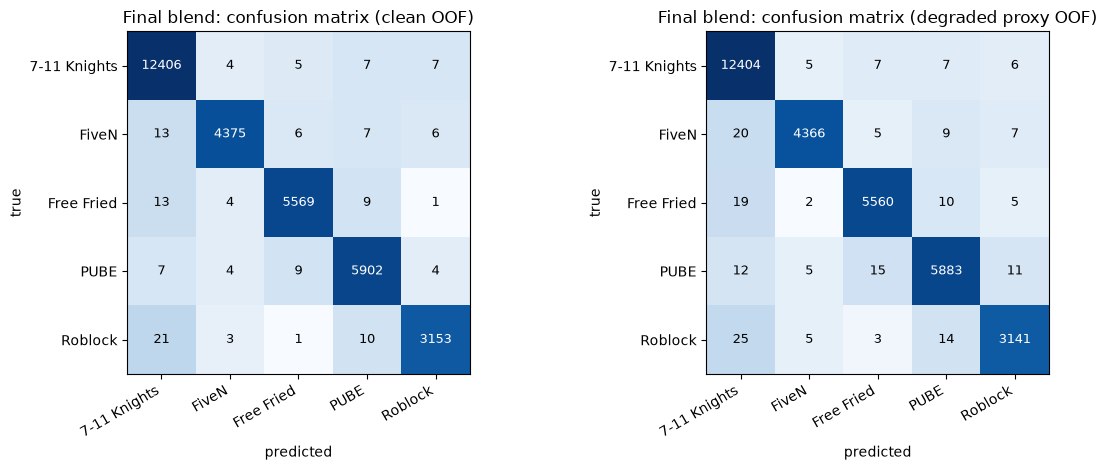

In [9]:
W = cands['el5 + cl5 (final)']
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, key, name in [(axes[0], 'oof', 'clean'), (axes[1], 'oofc', 'degraded proxy')]:
    cm = confusion_matrix(y, blend(W, key).argmax(1))
    ax.imshow(np.log1p(cm), cmap='Blues')
    for i in range(5):
        for j in range(5):
            ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=9, color='white' if i == j else 'black')
    ax.set_xticks(range(5), CLASSES, rotation=30, ha='right'); ax.set_yticks(range(5), CLASSES)
    ax.set_xlabel('predicted'); ax.set_ylabel('true'); ax.set_title(f'Final blend: confusion matrix ({name} OOF)')
plt.tight_layout(); plt.show()

ความผิดพลาดที่เหลือมีจำนวนน้อยมากเมื่อเทียบกับขนาดของแต่ละคลาส และกลุ่มที่ใหญ่ที่สุดคือการทายผิดเป็น 7-11 Knights ซึ่งเป็นคลาสที่มีภาพมากที่สุดใน train
(เช่น ภาพ Roblock ถูกทายเป็น 7-11 Knights 21 ภาพ) บน degraded proxy ความผิดพลาดแบบนี้เพิ่มขึ้นเล็กน้อย แต่โดยรวมยังไม่มีคู่คลาสใดที่สับสนกันมาก

## 5. สร้างคำตอบสำหรับ test

In [10]:
test_p = {t: d['test'].mean(0) for t, d in P.items()}          # average of 5 fold models
final_p = sum(W[t] * test_p[t] for t in W) / sum(W.values())
pred = final_p.argmax(1)

agree = pd.DataFrame({a: {b: (test_p[a].argmax(1) == test_p[b].argmax(1)).mean() for b in test_p} for a in test_p})
print('test agreement between single models (share of rows with the same predicted class):')
print(agree.round(3).to_string())
print()
print('final predicted class counts:', dict(zip(CLASSES, np.bincount(pred, minlength=5).tolist())))

sub = pd.DataFrame({'id': test['id'], 'task4': pred})
assert (sub.id == [f'ANS{i + 1:05d}' for i in range(len(sub))]).all()
sub.to_csv(OUT / 'task4_pred.csv', index=False)

test agreement between single models (share of rows with the same predicted class):
       el5    cl5   eb5
el5  1.000  0.913  0.90
cl5  0.913  1.000  0.91
eb5  0.900  0.910  1.00

final predicted class counts: {'7-11 Knights': 4266, 'FiveN': 6621, 'Free Fried': 4074, 'PUBE': 6710, 'Roblock': 4218}


บน test โมเดลเดี่ยวเห็นตรงกันเพียงราว 90% ขณะที่บน validation ทุกโมเดลถูกเกิน 99%
แปลว่าภาพ test ยากกว่าภาพ train มาก และการรวมหลายสถาปัตยกรรมช่วยลดความผิดพลาดที่แต่ละโมเดลทำต่างกัน

## 6. สรุป

| ไฟล์คำตอบบน public leaderboard (Task 4 จากโมเดลที่ฝึกด้วย AUG 5) | คะแนนรวม 5 task |
|---|---|
| `cl5 + el5` อย่างละ 2 fold | 0.84127 |
| `cl5` 5 fold + `el5` 2 fold | 0.84173 |
| `cl5 + el5` อย่างละ 5 fold (คำตอบสุดท้าย) | **0.84253** |

- การรวม EVA02 Large กับ ConvNeXt V2 Large ให้ผลดีที่สุดทั้งบน OOF และบน leaderboard และการเพิ่มจำนวน fold ของแต่ละโมเดลช่วยเพิ่มคะแนนอย่างต่อเนื่อง
- ในรอบก่อนหน้า มีการใช้ augmentation ด้านสีที่รุนแรง (invert, หมุน hue, สลับช่องสี) ซึ่งออกแบบหลังจากเห็นภาพ test และได้คะแนน leaderboard สูงกว่า (0.84618)
  แต่ขัดกับกติกาที่ว่า augmentation ต้องไม่ถูกเลือกจากการดูข้อมูล test จึงตัดออกและฝึกโมเดลทั้งหมดใหม่ คะแนนรวมลดลงราว 0.0037 (ประมาณ 0.018 ของ macro F1 ใน Task 4)
- ได้ทดลอง AUG 6 (augmentation ที่แรงขึ้น) กับ ConvNeXt V2 Large หนึ่ง fold ผลบน fold นั้นน่าสนใจ แต่ฝึกไม่ครบ 5 fold ก่อนการแข่งขันจบ จึงไม่ได้นำมาใช้
- ตัวอย่างภาพในหัวข้อที่ 1 แสดงว่าภาพ train เองก็มีสีเพี้ยนหรือกลับสีอยู่แล้ว augmentation ด้านสีที่แรงขึ้นจึงสามารถออกแบบจากภาพ train ได้โดยตรง
  แต่ไม่ได้ทดลองแนวทางนี้ก่อนการแข่งขันจบ
- ช่องว่างระหว่าง validation (ราว 0.99) กับ test ยังกว้าง ทิศทางที่น่าทำต่อคือ augmentation ด้านสีที่อิงจากภาพ train, ฝึกโมเดลใหญ่หลาย seed และฝึก AUG 6 ให้ครบ 5 fold